# 0. Die einzelnen Angaben im Titanic-Datensatz

Welche Informationen haben wir über die Passagiere? Wir betrachten jede Spalte einzeln: Welche Werte kommen vor und welche Angaben fehlen?

Die Tabellen und Grafiken beschreiben 891 Personen mit bekanntem Überleben. Zusammenhänge mit dem Überleben untersuchen wir anschließend in [Notebook 1](01_Exploration.ipynb).


In [1]:
# Gestaltung der Abbildungen.
import json
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib import font_manager as fm
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
COLORS = {'dk2': '#732124', 'lt2': '#F0EDE5', 'accent1': '#D34817', 'accent2': '#A68D65', 'accent3': '#728377', 'accent4': '#B4797B', 'accent5': '#CE8439', 'accent6': '#CF3A2A', 'hlink': '#D06853', 'folHlink': '#B67779'}
MAJOR_FONTS = ('Rockwell Nova Light', 'Rockwell Nova', 'Rockwell', 'DejaVu Serif')
MINOR_FONTS = ('Avenir Next LT Pro Light', 'Avenir Next LT Pro', 'Avenir Next', 'Calibri Light', 'Calibri', 'DejaVu Sans')
LEAF_CMAP = LinearSegmentedColormap.from_list('leaf', [COLORS['lt2'], COLORS['accent4'], COLORS['dk2']])
LEAF_CMAP.set_bad(COLORS['lt2'])

def resolved_fonts():
    available = {font.name for font in fm.fontManager.ttflist}
    major = next((name for name in MAJOR_FONTS if name in available))
    minor = next((name for name in MINOR_FONTS if name in available))
    return {'requested_heading': MAJOR_FONTS[0], 'heading': major, 'requested_body': MINOR_FONTS[0], 'body': minor, 'heading_file': fm.findfont(fm.FontProperties(family=major)), 'body_file': fm.findfont(fm.FontProperties(family=minor))}

def apply_leaf_theme():
    fonts = resolved_fonts()
    mpl.rcParams.update({'font.family': fonts['body'], 'font.size': 11, 'font.weight': 'normal', 'text.color': COLORS['dk2'], 'figure.facecolor': COLORS['lt2'], 'axes.facecolor': COLORS['lt2'], 'savefig.facecolor': COLORS['lt2'], 'savefig.transparent': False, 'axes.edgecolor': COLORS['accent2'], 'axes.linewidth': 0.7, 'axes.labelcolor': COLORS['dk2'], 'axes.labelsize': 11, 'axes.labelpad': 10, 'axes.titlesize': 13, 'axes.titleweight': 'normal', 'axes.titlepad': 14, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True, 'axes.prop_cycle': cycler(color=[COLORS[f'accent{i}'] for i in range(1, 7)]), 'xtick.color': COLORS['dk2'], 'ytick.color': COLORS['dk2'], 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'xtick.major.size': 0, 'ytick.major.size': 0, 'xtick.major.pad': 7, 'ytick.major.pad': 7, 'grid.color': COLORS['accent2'], 'grid.alpha': 0.22, 'grid.linewidth': 0.6, 'grid.linestyle': '-', 'legend.frameon': False, 'legend.fontsize': 10, 'lines.linewidth': 1.7, 'patch.linewidth': 0.8, 'boxplot.boxprops.color': COLORS['dk2'], 'boxplot.whiskerprops.color': COLORS['dk2'], 'boxplot.capprops.color': COLORS['dk2'], 'boxplot.medianprops.color': COLORS['dk2'], 'boxplot.flierprops.markeredgecolor': COLORS['dk2'], 'boxplot.flierprops.markerfacecolor': COLORS['lt2'], 'savefig.dpi': 300})
    return fonts

def _wrap_to_width(text, renderer, font_properties, max_width):
    lines = []
    for paragraph in text.split('\n'):
        line = ''
        for word in paragraph.split():
            candidate = f'{line} {word}'.strip()
            width = renderer.get_text_width_height_descent(candidate, font_properties, False)[0]
            if line and width > max_width:
                lines.append(line)
                line = word
            else:
                line = candidate
        lines.append(line)
    return '\n'.join(lines)

def decorate_leaf_figure(fig, number, title, note):
    fonts = resolved_fonts()
    heading = fm.FontProperties(family=fonts['heading'], size=17)
    body = fm.FontProperties(family=fonts['body'], size=9)
    fig.set_facecolor(COLORS['lt2'])
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    width_pixels, height_pixels = (fig.bbox.width, fig.bbox.height)
    for ax in fig.axes:
        ax.set_title(deutsch(ax.get_title()))
        ax.set_xlabel(deutsch(ax.get_xlabel()))
        ax.set_ylabel(deutsch(ax.get_ylabel()))
    title_text = _wrap_to_width(title, renderer, heading, 0.91 * width_pixels)
    note_text = _wrap_to_width('Anmerkung. ' + note, renderer, body, 0.91 * width_pixels)
    number_label = f'{number:02d}' if isinstance(number, int) else str(number)
    top_label = fig.text(0.045, 0.965, f'ABBILDUNG {number_label}', color=COLORS['accent1'], family=fonts['body'], fontsize=9, va='top')
    title_artist = fig.text(0.045, 0.91, title_text, fontproperties=heading, color=COLORS['dk2'], va='top', linespacing=1.12)
    note_artist = fig.text(0.045, 0.035, note_text, fontproperties=body, color=COLORS['dk2'], va='bottom', linespacing=1.3)
    fig.canvas.draw()
    title_box = title_artist.get_window_extent(renderer)
    note_box = note_artist.get_window_extent(renderer)
    top = title_box.y0 / height_pixels - 0.055
    bottom = note_box.y1 / height_pixels + 0.055
    if top - bottom < 0.28:
        raise ValueError('Figure is too short for its title/note; increase figsize height.')
    if fig.legends:
        for legend in fig.legends:
            for text in legend.get_texts():
                text.set_text(deutsch(text.get_text()))
            legend.set_loc('upper center')
            legend.set_bbox_to_anchor((0.5, top))
        fig.canvas.draw()
        top = min((legend.get_window_extent(renderer).y0 / height_pixels for legend in fig.legends)) - 0.035
    for ax in fig.axes:
        ax.set_title(deutsch(ax.get_title()))
        ax.set_xlabel(deutsch(ax.get_xlabel()))
        ax.set_ylabel(deutsch(ax.get_ylabel()))
        if ax.get_legend() is not None:
            for text in ax.get_legend().get_texts():
                text.set_text(deutsch(text.get_text()))
        ax.set_facecolor(COLORS['lt2'])
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        is_colorbar = hasattr(ax, '_colorbar')
        if ax.images or is_colorbar:
            ax.grid(False)
        elif ax.axison:
            horizontal = any((getattr(container, 'orientation', None) == 'horizontal' for container in ax.containers))
            horizontal = horizontal or 'fehlender' in ax.get_xlabel() or ax.get_xlabel() == 'Beobachtete Überlebensquote'
            ax.grid(axis='x' if horizontal else 'y')
        ax.title.set_fontfamily(fonts['heading'])
        ax.set_axisbelow(True)
    fig.add_artist(Line2D([0.045, 0.12], [top + 0.027, top + 0.027], transform=fig.transFigure, color=COLORS['accent1'], linewidth=2.5, solid_capstyle='butt'))
    fig.add_artist(Line2D([0.045, 0.955], [bottom - 0.022, bottom - 0.022], transform=fig.transFigure, color=COLORS['accent2'], linewidth=0.6, alpha=0.55))
    fig.tight_layout(rect=[0.025, bottom, 0.98, top], pad=1.1, w_pad=2.5)
    return (top_label, title_artist, note_artist)

def save_leaf_figure(fig, number, title, note, destination, *, show=True, dpi=None):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    decorate_leaf_figure(fig, number, deutsch(title), deutsch(note))
    fig.savefig(destination.with_suffix('.png'), dpi=dpi)
    if show:
        plt.show()
    plt.close(fig)

import pandas as pd
from IPython.display import display as _display

BEZEICHNUNGEN = {
    'Accuracy': 'Genauigkeit', 'CV-Accuracy': 'Mittlere Prüfgenauigkeit',
    'CV-F1': 'Mittlerer F1-Wert', 'CV-ROC AUC': 'Mittlere Fläche unter der Prüfkurve',
    'CV-Brier': 'Mittlerer Wahrscheinlichkeitsfehler', 'Fold-SD': 'Streuung der Prüfergebnisse',
    'Precision': 'Anteil richtiger Überlebensvorhersagen', 'Recall': 'Anteil erkannter Überlebender',
    'F1': 'F1-Wert', 'ROC AUC': 'Fläche unter der Prüfkurve',
    'Brier score': 'Wahrscheinlichkeitsfehler', "Cohen's kappa": 'Übereinstimmung über Zufallsniveau',
    'Feature': 'Merkmal', 'Coefficient': 'Gewicht', 'Feature importance': 'Merkmalsbedeutung',
    'Distance': 'Abstand', 'VoteWeight': 'Stimmgewicht', 'VoteShare': 'Stimmanteil',
    'Mean': 'Mittelwert', 'Standard deviation': 'Standardabweichung',
    '25% Quantile': 'Unteres Viertel', '75% Quantile': 'Oberes Viertel',
    'Binary target': 'Ergebnis mit zwei Werten', 'Ordinal category': 'Geordnete Kategorie',
    'Nominal category': 'Ungeordnete Kategorie', 'Candidate': 'Kombination',
    'Fold': 'Prüfdurchgang', 'Rank': 'Rang', 'Training': 'Genauigkeit in den Lerndaten',
    'Encoded columns': 'Anzahl aufbereiteter Merkmale',
    'Known holdout Accuracy': 'Genauigkeit im Kontrollvergleich',
    'Nested Personen Accuracy': 'Zusätzliche Prüfgenauigkeit (Personen)',
    'Nested Ticketgruppen Accuracy': 'Zusätzliche Prüfgenauigkeit (Ticketgruppen)',
    'Logistic Regression': 'Logistische Regression', 'Decision Tree': 'Entscheidungsbaum',
    'Shallow Decision Tree': 'Einfacher Entscheidungsbaum',
    'Extended Decision Tree': 'Erweiterter Entscheidungsbaum',
    'female': 'Weiblich', 'n_neighbors': 'Anzahl Nachbarn', 'p': 'Abstandsmaß', 'weights': 'Gewichtung', 'uniform': 'Gleichmäßig', 'distance': 'Nach Abstand', 'male': 'Männlich', 'Other': 'Sonstige',
    'Train': 'Trainingsdaten', 'Kaggle-Test': 'Testdaten',
}

def display(*werte):
    for wert in werte:
        if isinstance(wert, (pd.DataFrame, pd.Series)):
            wert = wert.copy()
            if isinstance(wert, pd.Series):
                wert = wert.to_frame()
            wert = wert.rename(columns=BEZEICHNUNGEN, index=BEZEICHNUNGEN)
            for spalte in wert.select_dtypes(include=['object', 'str']).columns:
                wert[spalte] = wert[spalte].replace(BEZEICHNUNGEN)
        if isinstance(wert, Markdown):
            wert = Markdown(deutsch(wert.data))
        _display(wert)


def deutsch(text):
    for vorher, nachher in {
        'Logistic Regression': 'Logistische Regression',
        'Shallow Decision Tree': 'Einfacher Entscheidungsbaum',
        'Extended Decision Tree': 'Erweiterter Entscheidungsbaum',
        'Decision Tree': 'Entscheidungsbaum',
        'Confusion Matrices': 'Richtige und falsche Vorhersagen',
        'Accuracy': 'Genauigkeit', 'Nested Personen-CV': 'zusätzlichen Personenprüfung',
        'Nested CV': 'zusätzliche Prüfung der Auswahl',
        'Outer fold': 'äußerer Prüfdurchgang', 'Auswahl-Folds': 'Prüfdurchgänge',
        'Training fold': 'Lerngruppe', 'Training folds': 'Lerngruppen',
        'Bekanntes Holdout': 'Kontrollvergleich', 'bekanntes Holdout': 'Kontrollvergleich', 'Holdout': 'Kontrolldatensatz',
        'Featuregruppe': 'Merkmalsgruppe', 'Feature': 'Merkmal',
        'Mean': 'Mittelwert', 'Target': 'Überleben',
        'standardized': 'bei gleicher Gruppenzusammensetzung',
        'Standardization': 'Angleichung der Gruppenzusammensetzung',
        'Median Imputation': 'Ergänzung mit dem mittleren Wert',
        'Labels': 'bekannte Ergebnisse', 'labels': 'bekannte Ergebnisse',
        'Log-Odds': 'Gewichte im Modell', 'Preprocessing': 'Datenvorbereitung',
        'Train:': 'Trainingsdaten:', 'Train (': 'Trainingsdaten (',
        'vollständigem Train': 'vollständigen Trainingsdaten',
        'nur Train': 'nur Trainingsdaten', '(Train)': '(Trainingsdaten)',
        'Nutzergrenzen nach Deckplänen': 'Vereinfachte Zuordnung',
        'keine testseitigen Überlebenslabels': 'Überleben der Testpersonen unbekannt',
        'Standardentscheidung': 'gewöhnliche Entscheidungsregel',
        'getunte Auswahlwerte sind optimistisch': 'die besten Auswahlwerte können zu günstig ausfallen',
        'CV': 'Kreuzvalidierung', 'Folds': 'Prüfgruppen',
        'female': 'weiblich', 'male': 'männlich',
    }.items():
        text = text.replace(vorher, nachher)
    return text




In [2]:
from pathlib import Path
import re
import sys
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import Markdown
pd.set_option('display.precision', 3)
ERGEBNISSE = Path('ergebnisse/00_univariat')
ABBILDUNGEN = Path('abbildungen/00_univariat')
ERGEBNISSE.mkdir(parents=True, exist_ok=True)
ABBILDUNGEN.mkdir(parents=True, exist_ok=True)



## Unsere Daten

`train.csv` enthält 891 Personen mit bekanntem Überleben. `test.csv` enthält 418 weitere Personen, für die wir später Vorhersagen erstellen.

Hier beschreiben wir alle 891 Trainingspersonen. Die Aufteilung für den Modellvergleich folgt in Notebook 3. Tabellen stehen direkt im Notebook; die Grafiken werden zusätzlich im Ordner `abbildungen` gespeichert.


In [3]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
analyse = train.copy()
assert len(analyse) == 891 and analyse.PassengerId.is_unique
print(deutsch(f'Train: {len(train)}; Testdaten: {len(test)}; Analyse: {len(analyse)}'))
print(deutsch(f'Originalspalten: {len(analyse.columns)}; vollständige doppelte Zeilen: {analyse.duplicated().sum()}'))



Trainingsdaten: 891; Testdaten: 418; Analyse: 891
Originalspalten: 12; vollständige doppelte Zeilen: 0


In [4]:
font_info = apply_leaf_theme()
PRIMAER, SEKUNDAER, FEHLEND = (COLORS['accent1'], COLORS['accent3'], COLORS['accent2'])

def abbildung(fig, nummer, titel, anmerkung, dateiname):
    save_leaf_figure(fig, nummer, titel, anmerkung, ABBILDUNGEN / dateiname)

def kennzahlen(werte, dateiname):
    beobachtet = werte.dropna()
    tabelle = pd.Series({'Personen gesamt': len(werte), 'Beobachtet': len(beobachtet), 'Fehlend': werte.isna().sum(), 'Unterschiedliche Werte': beobachtet.nunique(), 'Mean': beobachtet.mean(), 'Standard deviation': beobachtet.std(ddof=1), 'Minimum': beobachtet.min(), '25% Quantile': beobachtet.quantile(0.25), 'Median': beobachtet.median(), '75% Quantile': beobachtet.quantile(0.75), 'Maximum': beobachtet.max(), 'Interquartile range (IQR)': beobachtet.quantile(0.75) - beobachtet.quantile(0.25), 'Skewness': beobachtet.skew(), 'Nullwerte': beobachtet.eq(0).sum()}, name=werte.name).to_frame()
    display(tabelle)
    return tabelle

def kategorien(werte, reihenfolge, beschriftungen, nummer, titel, anmerkung, dateiname):
    counts = werte.astype('object').where(werte.notna(), 'Fehlt').value_counts()
    reihenfolge = list(reihenfolge)
    if 'Fehlt' in counts and 'Fehlt' not in reihenfolge:
        reihenfolge.append('Fehlt')
    counts = counts.reindex(reihenfolge, fill_value=0)
    assert counts.sum() == len(werte)
    tabelle = pd.DataFrame({'Anzahl': counts, 'Anteil': counts / len(werte)})
    tabelle.index = [beschriftungen.get(k, str(k)) for k in counts.index]
    tabelle.index.name = 'Kategorie'
    display(tabelle)
    fig, ax = plt.subplots(figsize=(8.5, max(4.8, 2.5 + 0.42 * len(counts))))
    positionen = np.arange(len(counts))
    farben = [FEHLEND if k == 'Fehlt' else PRIMAER for k in counts.index]
    ax.barh(positionen, tabelle.Anteil, color=farben, height=0.58)
    for i, (_, zeile) in enumerate(tabelle.iterrows()):
        ax.text(zeile.Anteil + 0.012, i, f'{int(zeile.Anzahl)} ({zeile.Anteil:.1%})', va='center', fontsize=9)
    ax.set(yticks=positionen, yticklabels=tabelle.index, xlabel='Anteil', xlim=(0, 1.15))
    ax.set_xticks(np.arange(0, 1.01, 0.2))
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.invert_yaxis()
    abbildung(fig, nummer, titel, anmerkung, dateiname)
    return tabelle



## Überblick über die Angaben

Wir prüfen, was die Spalten bedeuten und wie viele Werte fehlen. Zahlen können unterschiedliche Bedeutungen haben: Die Ticketklasse ist eine geordnete Kategorie, die Personennummer nur eine Kennung.


,Bedeutung / Typ,CSV-Datentyp,Beobachtet (n),Fehlend (n),Fehlend (%),Unterschiedliche beobachtete Werte
PassengerId,Kennung,int64,891,0,0.000,891
Survived,Ergebnis mit zwei Werten,int64,891,0,0.000,2
Pclass,Geordnete Kategorie,int64,891,0,0.000,3
Name,Zeichenfolge,str,891,0,0.000,891
Sex,Ungeordnete Kategorie,str,891,0,0.000,2
Age,"Numerisch, Jahre",float64,714,177,19.865,88
SibSp,Diskrete Anzahl,int64,891,0,0.000,7
Parch,Diskrete Anzahl,int64,891,0,0.000,7
Ticket,Zeichenfolge / Gruppenkennung,str,891,0,0.000,681
Fare,"Numerisch, erfasster Fahrpreis",float64,891,0,0.000,248


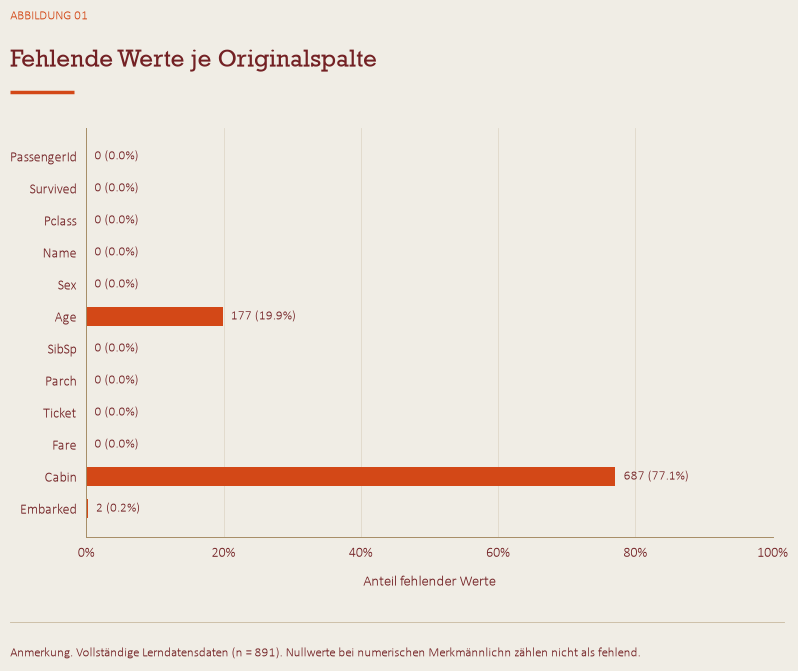

In [5]:
rollen = {'PassengerId': 'Kennung', 'Survived': 'Binary target', 'Pclass': 'Ordinal category', 'Name': 'Zeichenfolge', 'Sex': 'Nominal category', 'Age': 'Numerisch, Jahre', 'SibSp': 'Diskrete Anzahl', 'Parch': 'Diskrete Anzahl', 'Ticket': 'Zeichenfolge / Gruppenkennung', 'Fare': 'Numerisch, erfasster Fahrpreis', 'Cabin': 'Zeichenfolge', 'Embarked': 'Nominal category'}
ueberblick = pd.DataFrame({'Bedeutung / Typ': pd.Series(rollen), 'CSV-Datentyp': analyse.dtypes.astype(str), 'Beobachtet (n)': analyse.notna().sum(), 'Fehlend (n)': analyse.isna().sum(), 'Fehlend (%)': 100 * analyse.isna().mean(), 'Unterschiedliche beobachtete Werte': analyse.nunique(dropna=True)}).loc[analyse.columns]
display(ueberblick)
ueberblick.to_csv(ERGEBNISSE / 'merkmalsueberblick.csv')
fig, ax = plt.subplots(figsize=(8.5, 7.0))
positionen = np.arange(len(analyse.columns))
anteile = analyse.isna().mean()
ax.barh(positionen, anteile, color=PRIMAER, height=0.6)
for i, spalte in enumerate(analyse.columns):
    ax.text(anteile[spalte] + 0.012, i, f'{analyse[spalte].isna().sum()} ({anteile[spalte]:.1%})', va='center', fontsize=9)
ax.set(yticks=positionen, yticklabels=analyse.columns, xlabel='Anteil fehlender Werte', xlim=(0, 1))
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.invert_yaxis()
abbildung(fig, 1, 'Fehlende Werte je Originalspalte', 'Vollständige Trainingsdaten (n = 891). Nullwerte bei numerischen Merkmalen zählen nicht als fehlend.', '01_fehlende_werte')



### Welche Arten von Angaben gibt es?

Geschlecht und Einstiegsort sind Kategorien ohne Reihenfolge. Die Ticketklassen haben eine Reihenfolge. Alter, Fahrpreis und die Anzahl von Angehörigen sind messbare Größen.

Namen, Ticketnummern und Kabinenangaben sind Textfelder. `Survived` beschreibt das Ergebnis, das wir später vorhersagen möchten.


,Originalspalte,Skalengruppe,Beschreibung
0,PassengerId,Nominal,Kennung; kein Eingabemerkmal
1,Survived,Nominal,Überleben; kein Eingabemerkmal
2,Name,Nominal,Individuelles Textfeld
3,Sex,Nominal,Ungeordnete Geschlechtskategorie
4,Ticket,Nominal,Ticketkennung / Textfeld
5,Cabin,Nominal,Kabinenkennung / Textfeld
6,Embarked,Nominal,Ungeordneter Einstiegsort
7,Pclass,Kategorial (ordinal),"Geordnete Ticketklasse: 1, 2, 3"
8,Age,Metrisch,Alter in Jahren
9,SibSp,Metrisch,Diskrete Anzahl Geschwister/Partner


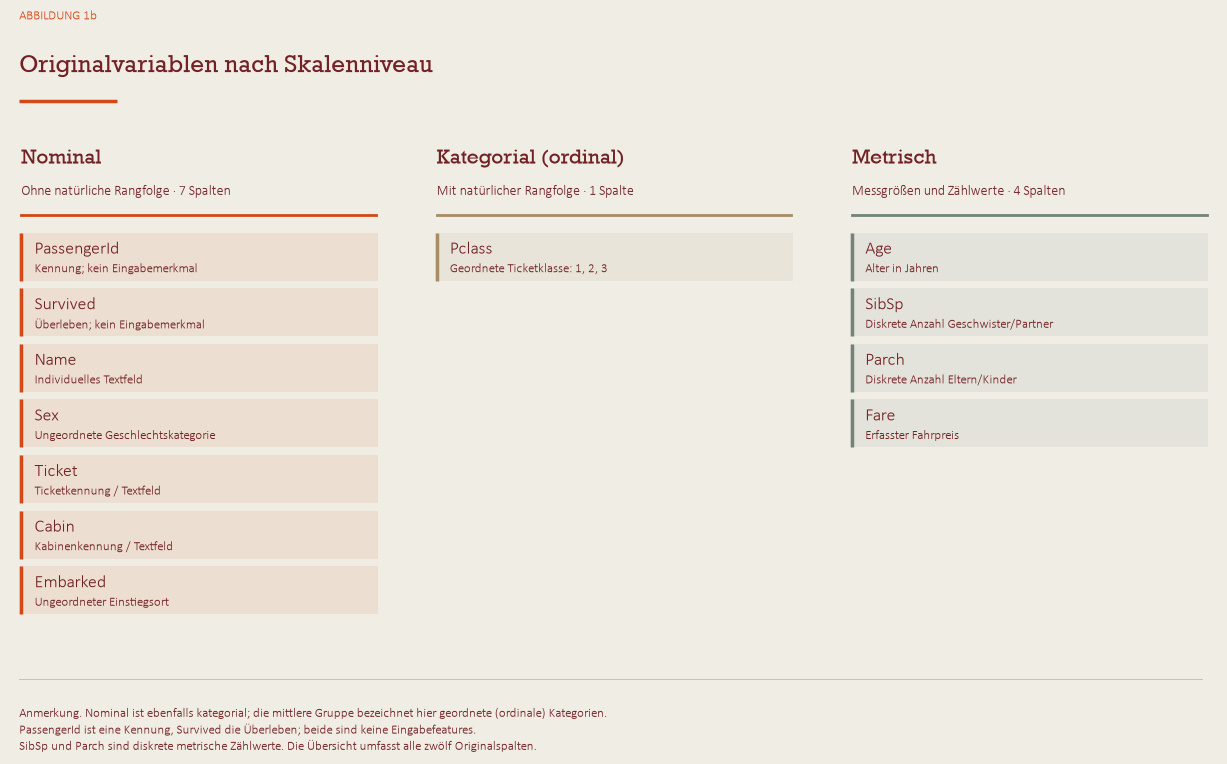

In [6]:
skalen_gruppen = {'Nominal': [('PassengerId', 'Kennung; kein Eingabemerkmal'), ('Survived', 'Überleben; kein Eingabemerkmal'), ('Name', 'Individuelles Textfeld'), ('Sex', 'Ungeordnete Geschlechtskategorie'), ('Ticket', 'Ticketkennung / Textfeld'), ('Cabin', 'Kabinenkennung / Textfeld'), ('Embarked', 'Ungeordneter Einstiegsort')], 'Kategorial (ordinal)': [('Pclass', 'Geordnete Ticketklasse: 1, 2, 3')], 'Metrisch': [('Age', 'Alter in Jahren'), ('SibSp', 'Diskrete Anzahl Geschwister/Partner'), ('Parch', 'Diskrete Anzahl Eltern/Kinder'), ('Fare', 'Erfasster Fahrpreis')]}
feature_skalen = pd.DataFrame([{'Originalspalte': feature, 'Skalengruppe': gruppe, 'Beschreibung': beschreibung} for gruppe, eintraege in skalen_gruppen.items() for feature, beschreibung in eintraege])
assert feature_skalen.Originalspalte.is_unique
assert set(feature_skalen.Originalspalte) == set(analyse.columns)
feature_skalen.to_csv(ERGEBNISSE / 'feature_skalen.csv', index=False)
display(feature_skalen)
fig, achsen = plt.subplots(1, 3, figsize=(13, 8))
gruppen_farben = [COLORS['accent1'], COLORS['accent2'], COLORS['accent3']]
definitionen = ['Ohne natürliche Rangfolge', 'Mit natürlicher Rangfolge', 'Messgrößen und Zählwerte']
for ax, (gruppe, eintraege), farbe, definition in zip(achsen, skalen_gruppen.items(), gruppen_farben, definitionen):
    ax.set(xlim=(0, 1), ylim=(0, 1))
    ax.set_axis_off()
    heading = 'Kategorial (ordinal)' if gruppe.startswith('Kategorial') else gruppe
    ax.text(0.03, 0.98, heading, color=COLORS['dk2'], family=font_info['heading'], fontsize=15, va='top', transform=ax.transAxes)
    ax.text(0.03, 0.91, f"{definition} · {len(eintraege)} Spalte{('n' if len(eintraege) != 1 else '')}", fontsize=10, color=COLORS['dk2'], va='top', transform=ax.transAxes)
    ax.plot([0.03, 0.97], [0.85, 0.85], color=farbe, linewidth=2, transform=ax.transAxes)
    for i, (feature, beschreibung) in enumerate(eintraege):
        y = 0.79 - i * 0.11
        ax.add_patch(plt.Rectangle((0.025, y - 0.07), 0.95, 0.095, facecolor=farbe, alpha=0.09, edgecolor='none', transform=ax.transAxes))
        ax.plot([0.03, 0.03], [y - 0.07, y + 0.025], color=farbe, linewidth=2.5, transform=ax.transAxes, solid_capstyle='butt')
        ax.text(0.065, y + 0.01, feature, color=COLORS['dk2'], fontsize=13, va='top', transform=ax.transAxes)
        ax.text(0.065, y - 0.035, beschreibung, color=COLORS['dk2'], fontsize=9, va='top', transform=ax.transAxes)
abbildung(fig, '1b', 'Originalvariablen nach Skalenniveau', 'Nominal ist ebenfalls kategorial; die mittlere Gruppe bezeichnet hier geordnete (ordinale) Kategorien.\nPassengerId ist eine Kennung, Survived die Target; beide sind keine Eingabefeatures.\nSibSp und Parch sind diskrete metrische Zählwerte. Die Übersicht umfasst alle zwölf Originalspalten.', '01b_feature_skalen')



## PassengerId: Nummer der Person

Die Nummer hilft, jede Vorhersage der richtigen Person zuzuordnen. Ein Durchschnitt dieser Nummern hätte keine inhaltliche Bedeutung.


In [7]:
id_uebersicht = pd.Series({'Personen': len(analyse), 'Fehlende Kennungen': analyse.PassengerId.isna().sum(), 'Eindeutige Kennungen': analyse.PassengerId.nunique(), 'Doppelte Kennungen': analyse.PassengerId.duplicated().sum(), 'Kleinste Kennung': analyse.PassengerId.min(), 'Größte Kennung': analyse.PassengerId.max(), 'Gemeinsame Kennungen von train und test': len(set(train.PassengerId) & set(test.PassengerId))}, name='Wert').to_frame()
display(id_uebersicht)



,Wert
Personen,891
Fehlende Kennungen,0
Eindeutige Kennungen,891
Doppelte Kennungen,0
Kleinste Kennung,1
Größte Kennung,891
Gemeinsame Kennungen von train und test,0


## Survived: Hat die Person überlebt?

`0` bedeutet nicht überlebt, `1` bedeutet überlebt. Der Anteil der Einsen ist die beobachtete Überlebensquote. Wie gut ein Modell vorhersagt, wird erst später geprüft.


,Anzahl,Anteil
Kategorie,,
Nicht überlebt (0),549,0.616
Überlebt (1),342,0.384


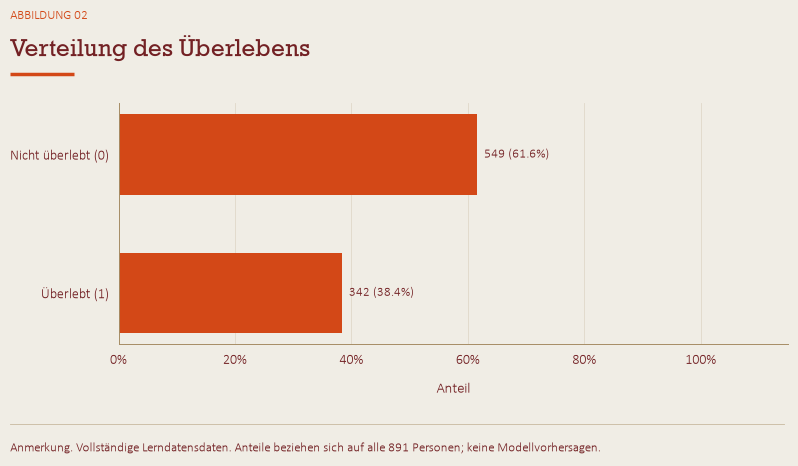

Beobachtete Überlebensquote: **38.4%**.

In [8]:
survived_haeufigkeiten = kategorien(analyse.Survived, [0, 1], {0: 'Nicht überlebt (0)', 1: 'Überlebt (1)'}, 2, 'Verteilung des Überlebens', 'Vollständige Trainingsdaten. Anteile beziehen sich auf alle 891 Personen; keine Modellvorhersagen.', '02_survived')
display(Markdown(f'Beobachtete Überlebensquote: **{analyse.Survived.mean():.1%}**.'))



## Pclass: Ticketklasse

Die Werte 1, 2 und 3 stehen für die drei Ticketklassen. Wir zählen, wie viele Personen zu jeder Klasse gehören.


,Anzahl,Anteil
Kategorie,,
1. Klasse,216,0.242
2. Klasse,184,0.207
3. Klasse,491,0.551


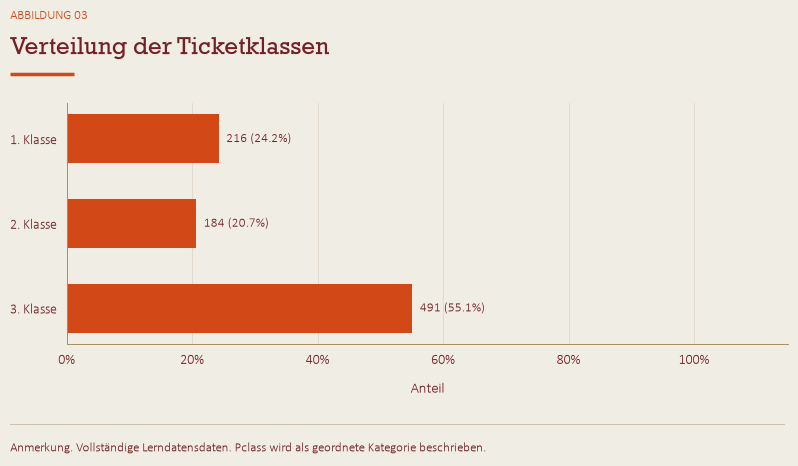

Häufigste Ticketklasse: **3**.

In [9]:
pclass_haeufigkeiten = kategorien(analyse.Pclass, [1, 2, 3], {1: '1. Klasse', 2: '2. Klasse', 3: '3. Klasse'}, 3, 'Verteilung der Ticketklassen', 'Vollständige Trainingsdaten. Pclass wird als geordnete Kategorie beschrieben.', '03_pclass')
display(Markdown(f'Häufigste Ticketklasse: **{analyse.Pclass.mode().iloc[0]}**.'))



## Name: Namen und enthaltene Titel

Die Namen sind überwiegend verschieden. Wir betrachten ihre Länge und Titel wie Mr, Mrs oder Dr. Seltene Titel werden für die Grafik zusammengefasst. Mögliche Hinweise auf die gesellschaftliche Stellung untersuchen wir in Notebook 2.


,Wert
Personen,891
Fehlende Namen,0
Unterschiedliche Namen,891
Doppelte Namen,0


,Anzahl,Anteil
Titel,,
Mr,517,0.580
Miss,182,0.204
Mrs,125,0.140
Master,40,0.045
Dr,7,0.008
Rev,6,0.007
Major,2,0.002
Mlle,2,0.002
Col,2,0.002


,Anzahl,Anteil
Kategorie,,
Mr,517,0.580
Miss,182,0.204
Mrs,125,0.140
Master,40,0.045
Dr,7,0.008
Rev,6,0.007
Weitere Titel (n < 5),14,0.016


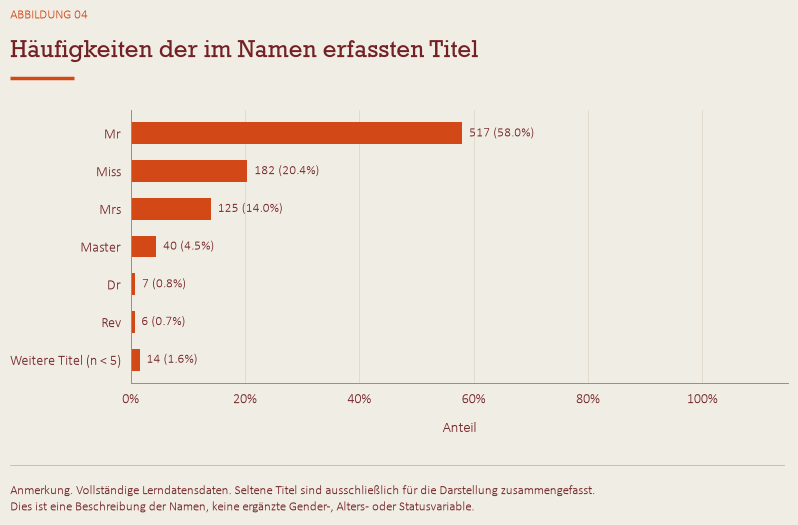

,Zeichen im Namen
Personen gesamt,891.000
Beobachtet,891.000
Fehlend,0.000
Unterschiedliche Werte,50.000
Mittelwert,26.965
Standardabweichung,9.282
Minimum,12.000
Unteres Viertel,20.000
Median,25.000
Oberes Viertel,30.000


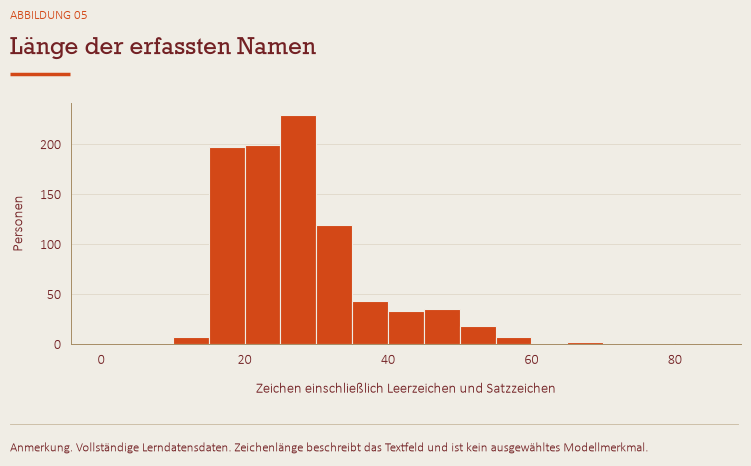

In [10]:
name_uebersicht = pd.Series({'Personen': len(analyse), 'Fehlende Namen': analyse.Name.isna().sum(), 'Unterschiedliche Namen': analyse.Name.nunique(), 'Doppelte Namen': analyse.Name.duplicated().sum()}, name='Wert').to_frame()
display(name_uebersicht)
titel = analyse.Name.str.extract(',\\s*([^.]*)\\.', expand=False).str.strip()
titel.name = 'Titel'
titel_counts = titel.fillna('Fehlt').value_counts()
display(pd.DataFrame({'Anzahl': titel_counts, 'Anteil': titel_counts / len(analyse)}))
haeufige_titel = titel_counts.loc[titel_counts >= 5].index
titel_grafik = titel.where(titel.isin(haeufige_titel), 'Weitere Titel (n < 5)')
name_titel_haeufigkeiten = kategorien(titel_grafik, [*haeufige_titel, 'Weitere Titel (n < 5)'], {}, 4, 'Häufigkeiten der im Namen erfassten Titel', 'Vollständige Trainingsdaten. Seltene Titel sind ausschließlich für die Darstellung zusammengefasst.\nDies ist eine Beschreibung der Namen, keine ergänzte Gender-, Alters- oder Statusvariable.', '04_name_titel')
name_laenge = analyse.Name.str.len().rename('Zeichen im Namen')
name_laenge_kennzahlen = kennzahlen(name_laenge, 'name_laenge')
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hist(name_laenge.dropna(), bins=np.arange(0, name_laenge.max() + 6, 5), color=PRIMAER, edgecolor=COLORS['lt2'])
ax.set(xlabel='Zeichen einschließlich Leerzeichen und Satzzeichen', ylabel='Personen')
abbildung(fig, 5, 'Länge der erfassten Namen', 'Vollständige Trainingsdaten. Zeichenlänge beschreibt das Textfeld und ist kein ausgewähltes Modellmerkmal.', '05_name_laenge')



## Sex: Erfasstes Geschlecht

`female` steht für weiblich, `male` für männlich. Die Grafik zeigt die Anzahl und Anteile dieser Gruppen.


,Anzahl,Anteil
Kategorie,,
Weiblich,314,0.352
Männlich,577,0.648


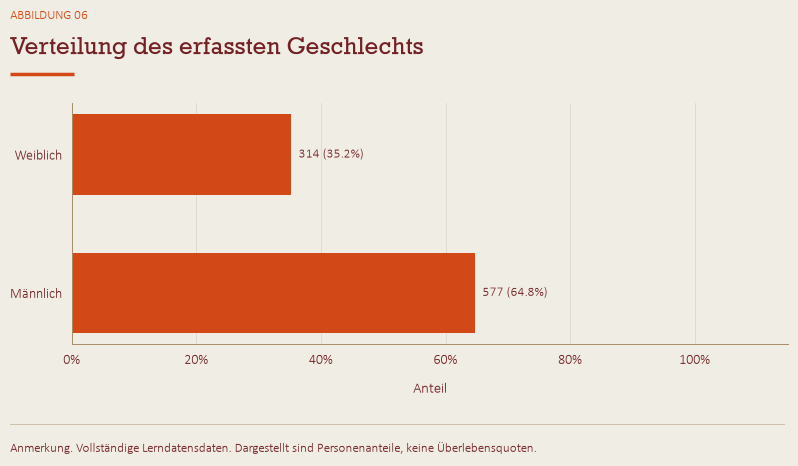

In [11]:
sex_haeufigkeiten = kategorien(analyse.Sex, ['female', 'male'], {'female': 'Weiblich', 'male': 'Männlich'}, 6, 'Verteilung des erfassten Geschlechts', 'Vollständige Trainingsdaten. Dargestellt sind Personenanteile, keine Überlebensquoten.', '06_sex')



## Age: Alter in Jahren

Einige Altersangaben fehlen. Die Kennzahlen verwenden nur bekannte Werte. Der Mittelwert ist das durchschnittliche Alter; der Median ist der mittlere Wert der sortierten Altersangaben.

Die Balken zeigen, wie viele Personen in den jeweiligen Altersbereichen liegen. Im Kastendiagramm umfasst die Box die mittlere Hälfte der Werte. Einzelne auffällige Werte bleiben erhalten.


,Age
Personen gesamt,891.000
Beobachtet,714.000
Fehlend,177.000
Unterschiedliche Werte,88.000
Mittelwert,29.699
Standardabweichung,14.526
Minimum,0.420
Unteres Viertel,20.125
Median,28.000
Oberes Viertel,38.000


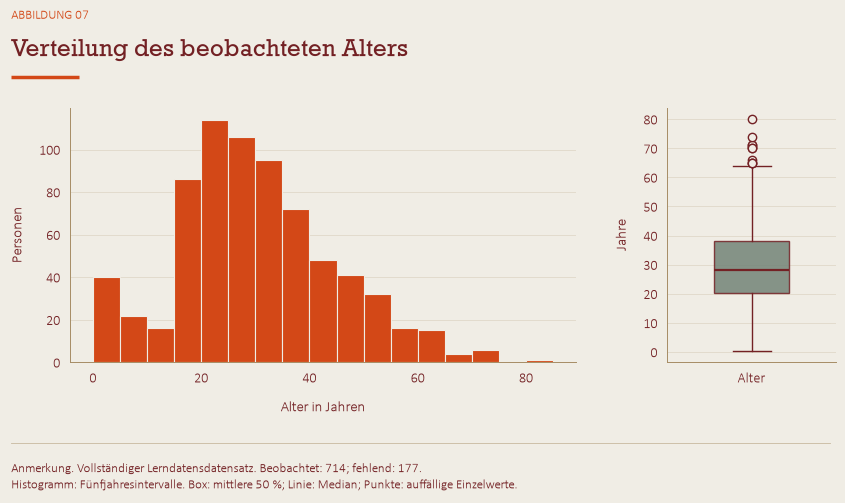

In [12]:
age_kennzahlen = kennzahlen(analyse.Age, 'age')
fig, achsen = plt.subplots(1, 2, figsize=(9, 5.2), gridspec_kw={'width_ratios': [3, 1]})
achsen[0].hist(analyse.Age.dropna(), bins=np.arange(0, 86, 5), color=PRIMAER, edgecolor=COLORS['lt2'])
achsen[0].set(xlabel='Alter in Jahren', ylabel='Personen')
box = achsen[1].boxplot(analyse.Age.dropna(), patch_artist=True, widths=0.45, medianprops={'color': COLORS['dk2'], 'linewidth': 1.6})
box['boxes'][0].set_facecolor(SEKUNDAER)
box['boxes'][0].set_alpha(0.85)
achsen[1].set(xticks=[1], xticklabels=['Alter'], ylabel='Jahre')
abbildung(fig, 7, 'Verteilung des beobachteten Alters', f'Vollständiger Trainingsdatensatz. Beobachtet: {analyse.Age.notna().sum()}; fehlend: {analyse.Age.isna().sum()}.\nHistogramm: Fünfjahresintervalle. Box: mittlere 50 %; Linie: Median; Punkte: auffällige Einzelwerte.', '07_age')



## SibSp: Geschwister und Ehepartner an Bord

Diese Angabe zählt erfasste Geschwister und Ehepartner. Eine Null ist gültig und bedeutet, dass hier keine solche Begleitung eingetragen ist.


,SibSp
Personen gesamt,891.000
Beobachtet,891.000
Fehlend,0.000
Unterschiedliche Werte,7.000
Mittelwert,0.523
Standardabweichung,1.103
Minimum,0.000
Unteres Viertel,0.000
Median,0.000
Oberes Viertel,1.000


,Anzahl,Anteil
Kategorie,,
0,608,0.682
1,209,0.235
2,28,0.031
3,16,0.018
4,18,0.020
5,5,0.006
8,7,0.008


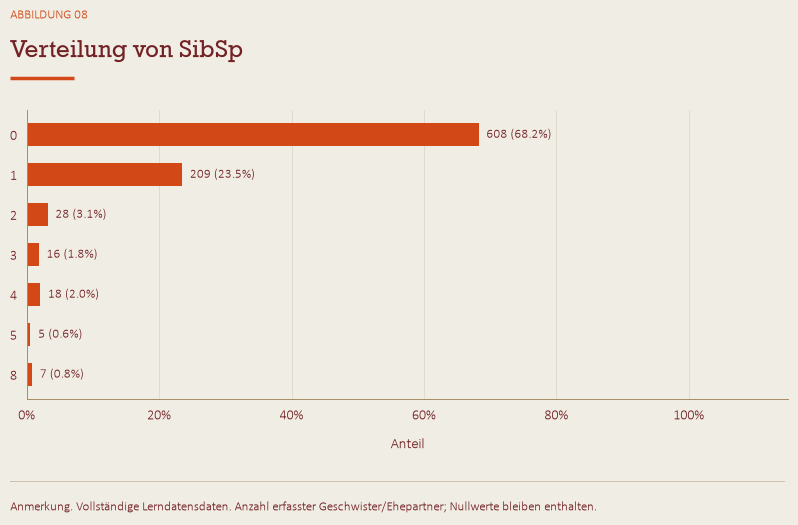

In [13]:
sibsp_kennzahlen = kennzahlen(analyse.SibSp, 'sibsp')
sibsp_haeufigkeiten = kategorien(analyse.SibSp, sorted(analyse.SibSp.dropna().unique()), {}, 8, 'Verteilung von SibSp', 'Vollständige Trainingsdaten. Anzahl erfasster Geschwister/Ehepartner; Nullwerte bleiben enthalten.', '08_sibsp')



## Parch: Eltern und Kinder an Bord

Diese Angabe zählt erfasste Eltern und Kinder. Andere Reisebegleiter werden damit nicht vollständig erfasst.


,Parch
Personen gesamt,891.000
Beobachtet,891.000
Fehlend,0.000
Unterschiedliche Werte,7.000
Mittelwert,0.382
Standardabweichung,0.806
Minimum,0.000
Unteres Viertel,0.000
Median,0.000
Oberes Viertel,0.000


,Anzahl,Anteil
Kategorie,,
0,678,0.761
1,118,0.132
2,80,0.090
3,5,0.006
4,4,0.004
5,5,0.006
6,1,0.001


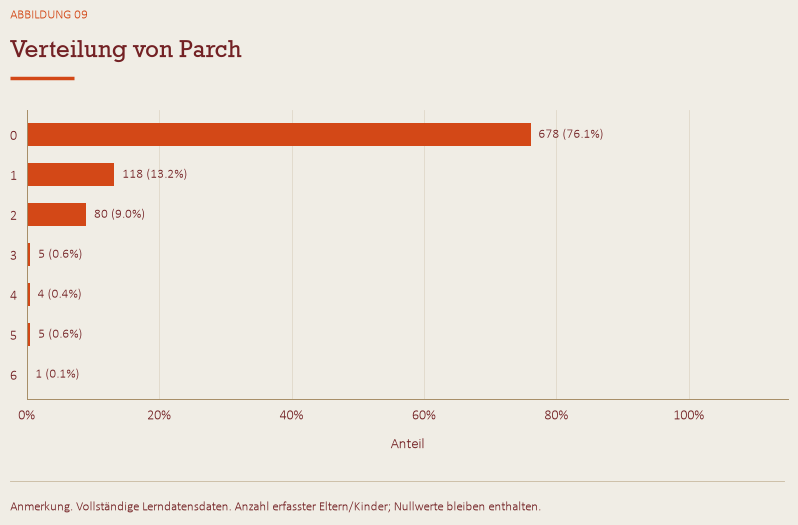

In [14]:
parch_kennzahlen = kennzahlen(analyse.Parch, 'parch')
parch_haeufigkeiten = kategorien(analyse.Parch, sorted(analyse.Parch.dropna().unique()), {}, 9, 'Verteilung von Parch', 'Vollständige Trainingsdaten. Anzahl erfasster Eltern/Kinder; Nullwerte bleiben enthalten.', '09_parch')



## Ticket: Ticketnummer

Mehrere Personen können dieselbe Ticketnummer haben. Wir zählen, wie oft das vorkommt. Das zeigt mögliche Reisegruppen, aber nicht zwingend die vollständige Gruppe.


,Wert
Personen,891
Fehlende Tickets,0
Unterschiedliche Originaltickets,681
Unterschiedliche normalisierte Tickets,681
Einmal vorkommende Tickets,547
Mehrfach vorkommende Tickets,134
Personen mit wiederholtem Ticket,344
Größte erfasste Häufigkeit eines Tickets,7


,Anzahl,Anteil
Kategorie,,
1,547,0.803
2,94,0.138
3,21,0.031
4,11,0.016
5,2,0.003
6,3,0.004
7,3,0.004


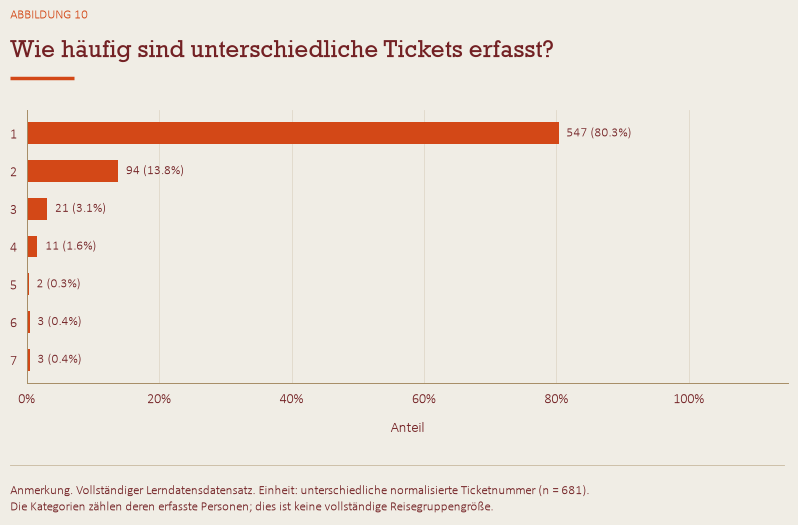

In [15]:
tickets = analyse.Ticket.str.strip().str.upper()
ticket_counts = tickets.dropna().value_counts()
ticket_uebersicht = pd.Series({'Personen': len(analyse), 'Fehlende Tickets': tickets.isna().sum(), 'Unterschiedliche Originaltickets': analyse.Ticket.nunique(), 'Unterschiedliche normalisierte Tickets': tickets.nunique(), 'Einmal vorkommende Tickets': ticket_counts.eq(1).sum(), 'Mehrfach vorkommende Tickets': ticket_counts.gt(1).sum(), 'Personen mit wiederholtem Ticket': tickets.duplicated(keep=False).sum(), 'Größte erfasste Häufigkeit eines Tickets': ticket_counts.max()}, name='Wert').to_frame()
display(ticket_uebersicht)
ticket_wiederholungen = kategorien(ticket_counts.rename('Personen je unterschiedlichem Ticket'), sorted(ticket_counts.unique()), {}, 10, 'Wie häufig sind unterschiedliche Tickets erfasst?', f'Vollständiger Trainingsdatensatz. Einheit: unterschiedliche normalisierte Ticketnummer (n = {len(ticket_counts)}).\nDie Kategorien zählen deren erfasste Personen; dies ist keine vollständige Reisegruppengröße.', '10_ticket_wiederholungen')



## Fare: Erfasster Fahrpreis

Wir betrachten die Verteilung der Fahrpreise einschließlich der Nullwerte. Sehr hohe Preise sind nicht automatisch Fehler. Ein gemeinsames Ticket kann mehrere Personen betreffen; der eingetragene Preis ist daher nicht immer der persönliche Preis.


,Fare
Personen gesamt,891.000
Beobachtet,891.000
Fehlend,0.000
Unterschiedliche Werte,248.000
Mittelwert,32.204
Standardabweichung,49.693
Minimum,0.000
Unteres Viertel,7.910
Median,14.454
Oberes Viertel,31.000


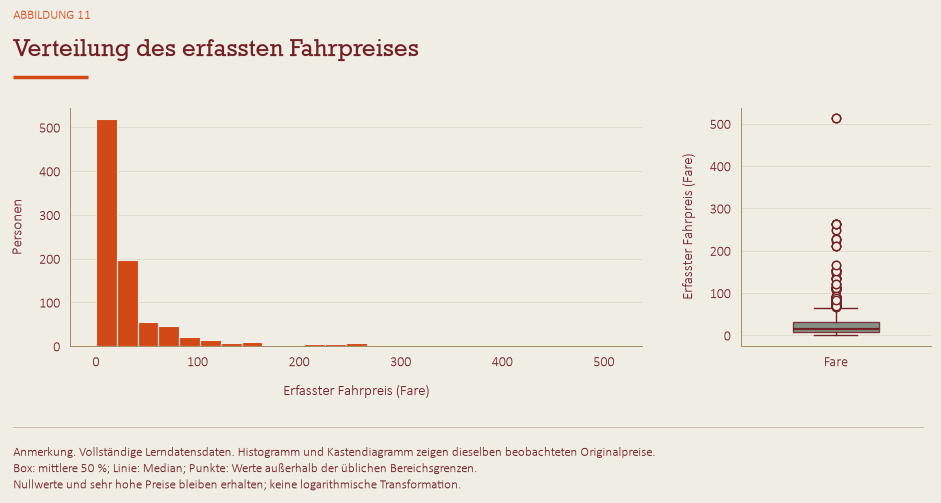

Mittelwert: **32.20**, Median: **14.45**. Der höhere Mittelwert beschreibt die lange rechte Seite der Preisverteilung.

In [16]:
fare_kennzahlen = kennzahlen(analyse.Fare, 'fare')
fig, achsen = plt.subplots(1, 2, figsize=(10, 5.2), gridspec_kw={'width_ratios': [3, 1]})
achsen[0].hist(analyse.Fare.dropna(), bins=25, color=PRIMAER, edgecolor=COLORS['lt2'])
achsen[0].set(xlabel='Erfasster Fahrpreis (Fare)', ylabel='Personen')
box = achsen[1].boxplot(analyse.Fare.dropna(), patch_artist=True, widths=0.45, medianprops={'color': COLORS['dk2'], 'linewidth': 1.6})
box['boxes'][0].set_facecolor(SEKUNDAER)
box['boxes'][0].set_alpha(0.85)
achsen[1].set(xticks=[1], xticklabels=['Fare'], ylabel='Erfasster Fahrpreis (Fare)')
abbildung(fig, 11, 'Verteilung des erfassten Fahrpreises', 'Vollständige Trainingsdaten. Histogramm und Kastendiagramm zeigen dieselben beobachteten Originalpreise.\nBox: mittlere 50 %; Linie: Median; Punkte: Werte außerhalb der üblichen Bereichsgrenzen.\nNullwerte und sehr hohe Preise bleiben erhalten; keine logarithmische Transformation.', '11_fare')
display(Markdown(f'Mittelwert: **{analyse.Fare.mean():.2f}**, Median: **{analyse.Fare.median():.2f}**. Der höhere Mittelwert beschreibt die lange rechte Seite der Preisverteilung.'))



## Cabin: Kabinenangabe

Für viele Personen fehlt die Kabine. Soweit möglich, ordnen wir vorhandene Angaben einem Deck von A bis G zu. Unbekannte oder widersprüchliche Angaben bleiben erkennbar. Fehlende Kabinen werden nicht geschätzt.


,Wert
Personen,891
Vorhandene Kabinenangaben,204
Fehlende Kabinenangaben,687
Unterschiedliche vorhandene Originalangaben,147
Angaben mit mehreren Textbestandteilen,24


,Anzahl,Anteil
Kategorie,,
Vorhanden,204,0.229
Fehlt,687,0.771


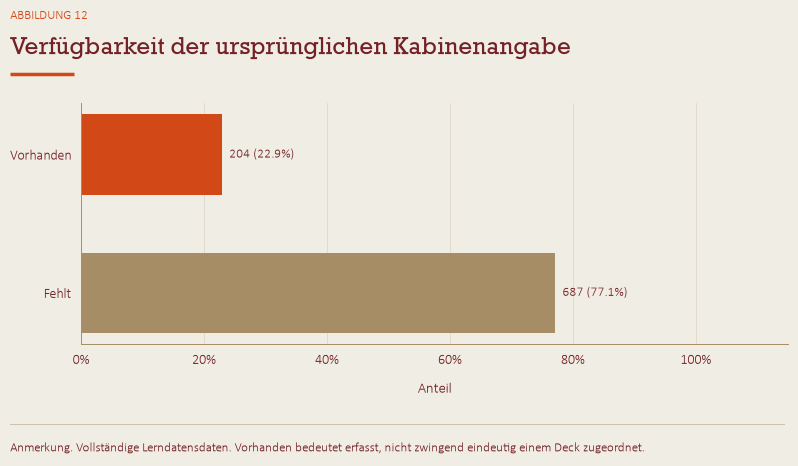

,Anzahl,Anteil
Kategorie,,
A,15,0.017
B,47,0.053
C,59,0.066
D,33,0.037
E,32,0.036
F,13,0.015
G,4,0.004
Nicht zuordenbar,1,0.001
Fehlt,687,0.771


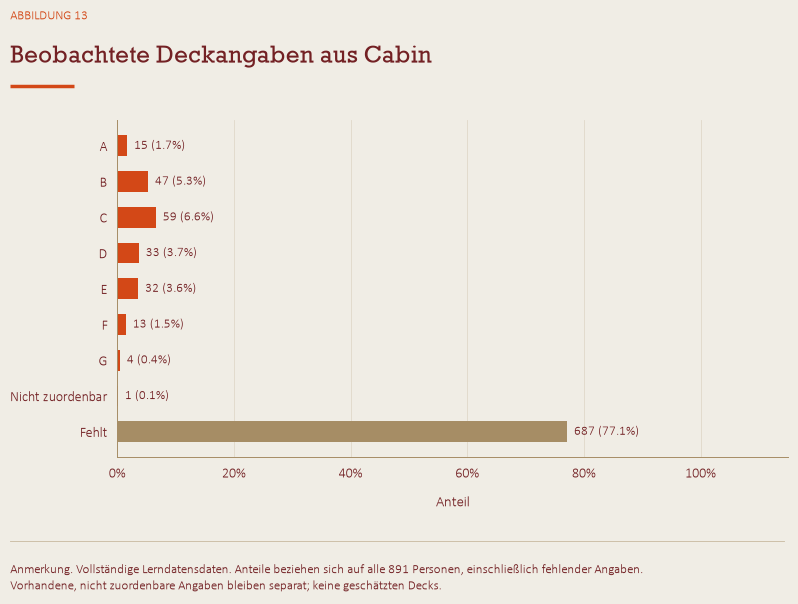

In [17]:
cabin_uebersicht = pd.Series({'Personen': len(analyse), 'Vorhandene Kabinenangaben': analyse.Cabin.notna().sum(), 'Fehlende Kabinenangaben': analyse.Cabin.isna().sum(), 'Unterschiedliche vorhandene Originalangaben': analyse.Cabin.nunique(), 'Angaben mit mehreren Textbestandteilen': analyse.Cabin.dropna().str.split().map(len).gt(1).sum()}, name='Wert').to_frame()
display(cabin_uebersicht)
cabin_erfasst = pd.Series(np.where(analyse.Cabin.notna(), 'Vorhanden', 'Fehlt'), index=analyse.index)
cabin_haeufigkeiten = kategorien(cabin_erfasst, ['Vorhanden', 'Fehlt'], {}, 12, 'Verfügbarkeit der ursprünglichen Kabinenangabe', 'Vollständige Trainingsdaten. Vorhanden bedeutet erfasst, nicht zwingend eindeutig einem Deck zugeordnet.', '12_cabin_erfassung')

def cabin_deck(kabine):
    if pd.isna(kabine):
        return 'Fehlt'
    text = kabine.strip().upper()
    if re.fullmatch('F [EG]\\d+', text):
        return 'F'
    teile = [re.fullmatch('([A-G])(\\d*)', teil) for teil in text.split()]
    if not teile or any((teil is None for teil in teile)):
        return 'Nicht zuordenbar'
    decks = {teil[1] for teil in teile}
    return decks.pop() if len(decks) == 1 else 'Nicht zuordenbar'
deckangaben = analyse.Cabin.map(cabin_deck)
deck_haeufigkeiten = kategorien(deckangaben, [*list('ABCDEFG'), 'Nicht zuordenbar', 'Fehlt'], {}, 13, 'Beobachtete Deckangaben aus Cabin', 'Vollständige Trainingsdaten. Anteile beziehen sich auf alle 891 Personen, einschließlich fehlender Angaben.\nVorhandene, nicht zuordenbare Angaben bleiben separat; keine geschätzten Decks.', '13_cabin_deck')



## Embarked: Einstiegsort

C steht für Cherbourg, Q für Queenstown und S für Southampton. Fehlende Angaben erscheinen als „Fehlt“.


,Anzahl,Anteil
Kategorie,,
C – Cherbourg,168,0.189
Q – Queenstown,77,0.086
S – Southampton,644,0.723
Fehlt,2,0.002


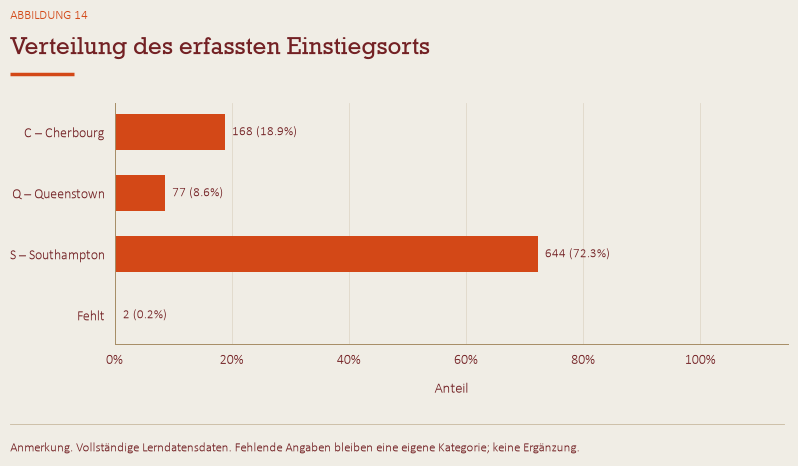

In [18]:
embarked_haeufigkeiten = kategorien(analyse.Embarked, ['C', 'Q', 'S'], {'C': 'C – Cherbourg', 'Q': 'Q – Queenstown', 'S': 'S – Southampton'}, 14, 'Verteilung des erfassten Einstiegsorts', 'Vollständige Trainingsdaten. Fehlende Angaben bleiben eine eigene Kategorie; keine Ergänzung.', '14_embarked')



## Was fällt auf?

- Besonders viele Kabinenangaben fehlen; auch das Alter ist nicht immer bekannt.
- Fahrpreise unterscheiden sich stark. Hohe Werte beeinflussen den Durchschnitt.
- Personennummern dienen der Zuordnung. Gemeinsame Tickets können auf Reisegruppen hinweisen.

Diese Beschreibung zeigt noch nicht, welche Angaben gute Vorhersagen ermöglichen. Das untersuchen wir in den folgenden Notebooks.

Weiter zu [Notebook 1: Zusammenhänge mit dem Überleben](01_Exploration.ipynb).


## Quellen

Daten: `train.csv` und `test.csv`. Aufgabenstellung: `Task_description.pdf`. Fachliche Grundlage: Lisa Grobelscheg, *Skriptum LV DSM, ITW 26/27* (`Skriptum.pdf`).

KI-Unterstützung wurde für Code, Abbildungen und Erklärungen verwendet.
